<a href="https://colab.research.google.com/github/vibhar5/4IK25CS237_DAV_LAB/blob/main/Wine_Quality_EDAES_project_4IK25CS237.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis of Wine Quality Dataset

**Project type:** Data Cleaning, Preprocessing, Exploratory Data Analysis (EDA), Visualization and Insights  
**Dataset source:** [UCI Machine Learning Repository – Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality)  
**Dataset file:** Red wine quality (`winequality-red.csv`)

## 1. Introduction
This project explores a real-world dataset containing physicochemical measurements of red wine and a quality score. The goal is to understand the data, clean and preprocess it, visualize important patterns, and draw evidence-based conclusions.

## 2. Objectives
- Load and inspect the dataset.
- Identify and handle missing values and duplicate records.
- Examine data types and descriptive statistics.
- Explore distributions, relationships and correlations.
- Create visualizations and summarize meaningful findings.

## 3. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 4. Load the dataset
The UCI dataset is a semicolon-separated CSV file. The code below downloads the red wine data directly. If the download is unavailable in your environment, download `winequality-red.csv` from the UCI page and upload it to Colab, then replace the URL with the uploaded filename.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 5. Understand the dataset
Check the number of rows and columns, column names, data types, and basic information.

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nDataset information:")
df.info()
print("\\nStatistical summary:")
display(df.describe().round(2))

Rows and columns: (1599, 12)
\nColumn names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               159

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


## 6. Data cleaning
Check for missing values and duplicate rows. Remove duplicate records so that repeated observations do not distort the analysis. Report the number of records removed.

In [4]:
print("Missing values in each column:")
display(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

print("Missing values after cleaning:", df.isnull().sum().sum())

Missing values in each column:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicate rows: 240
Shape after removing duplicates: (1359, 12)
Missing values after cleaning: 0


## 7. Data preprocessing
All columns should be numeric for this dataset. Confirm data types and check for impossible or unusual values using descriptive statistics. The `quality` column is the wine quality score and is treated as the target/outcome for descriptive comparisons.

In [5]:
print("Data types:")
display(df.dtypes)

print("Descriptive statistics after cleaning:")
display(df.describe().round(2))

# Confirm whether any non-numeric columns remain
print("Non-numeric columns:", df.select_dtypes(exclude=np.number).columns.tolist())

Data types:


,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Descriptive statistics after cleaning:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00
mean,8.31,0.53,0.27,2.52,0.09,15.89,46.83,1.00,3.31,0.66,10.43,5.62
std,1.74,0.18,0.20,1.35,0.05,10.45,33.41,0.00,0.16,0.17,1.08,0.82
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.43,2.60,0.09,21.00,63.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


Non-numeric columns: []


### 7.1 Outlier inspection using the IQR method
The IQR method flags observations outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. These are potential outliers, not automatically errors. We report their counts rather than deleting valid wine measurements.

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_counts = {}
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_counts[col] = int(((df[col] < lower) | (df[col] > upper)).sum())

outlier_summary = pd.Series(outlier_counts, name="Potential outlier count")
display(outlier_summary.sort_values(ascending=False))

,Potential outlier count
residual sugar,126
chlorides,87
sulphates,55
total sulfur dioxide,45
fixed acidity,41
density,35
pH,28
quality,27
free sulfur dioxide,26
volatile acidity,19


## 8. Exploratory Data Analysis (EDA)

### 8.1 Distribution of wine quality
This bar chart shows how frequently each quality score occurs.

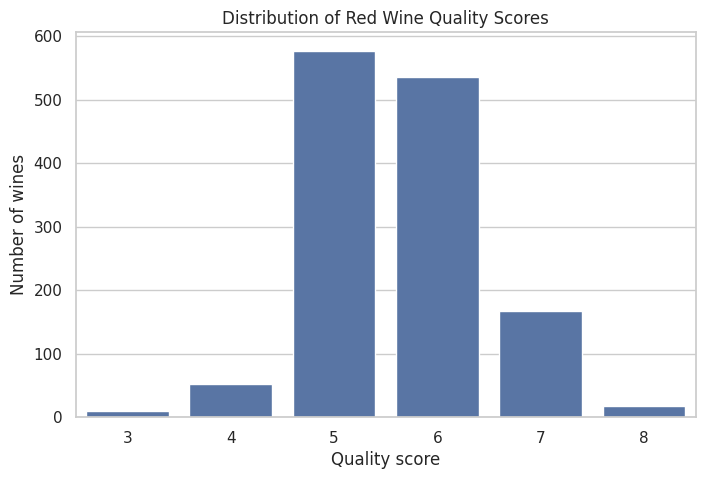

,Number of wines
quality,
3,10
4,53
5,577
6,535
7,167
8,17


In [7]:
quality_counts = df["quality"].value_counts().sort_index()
sns.barplot(x=quality_counts.index, y=quality_counts.values)
plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

display(quality_counts.rename("Number of wines"))

### 8.2 Distribution of numerical features
Histograms help identify skewness, spread, and common ranges for the measured variables.

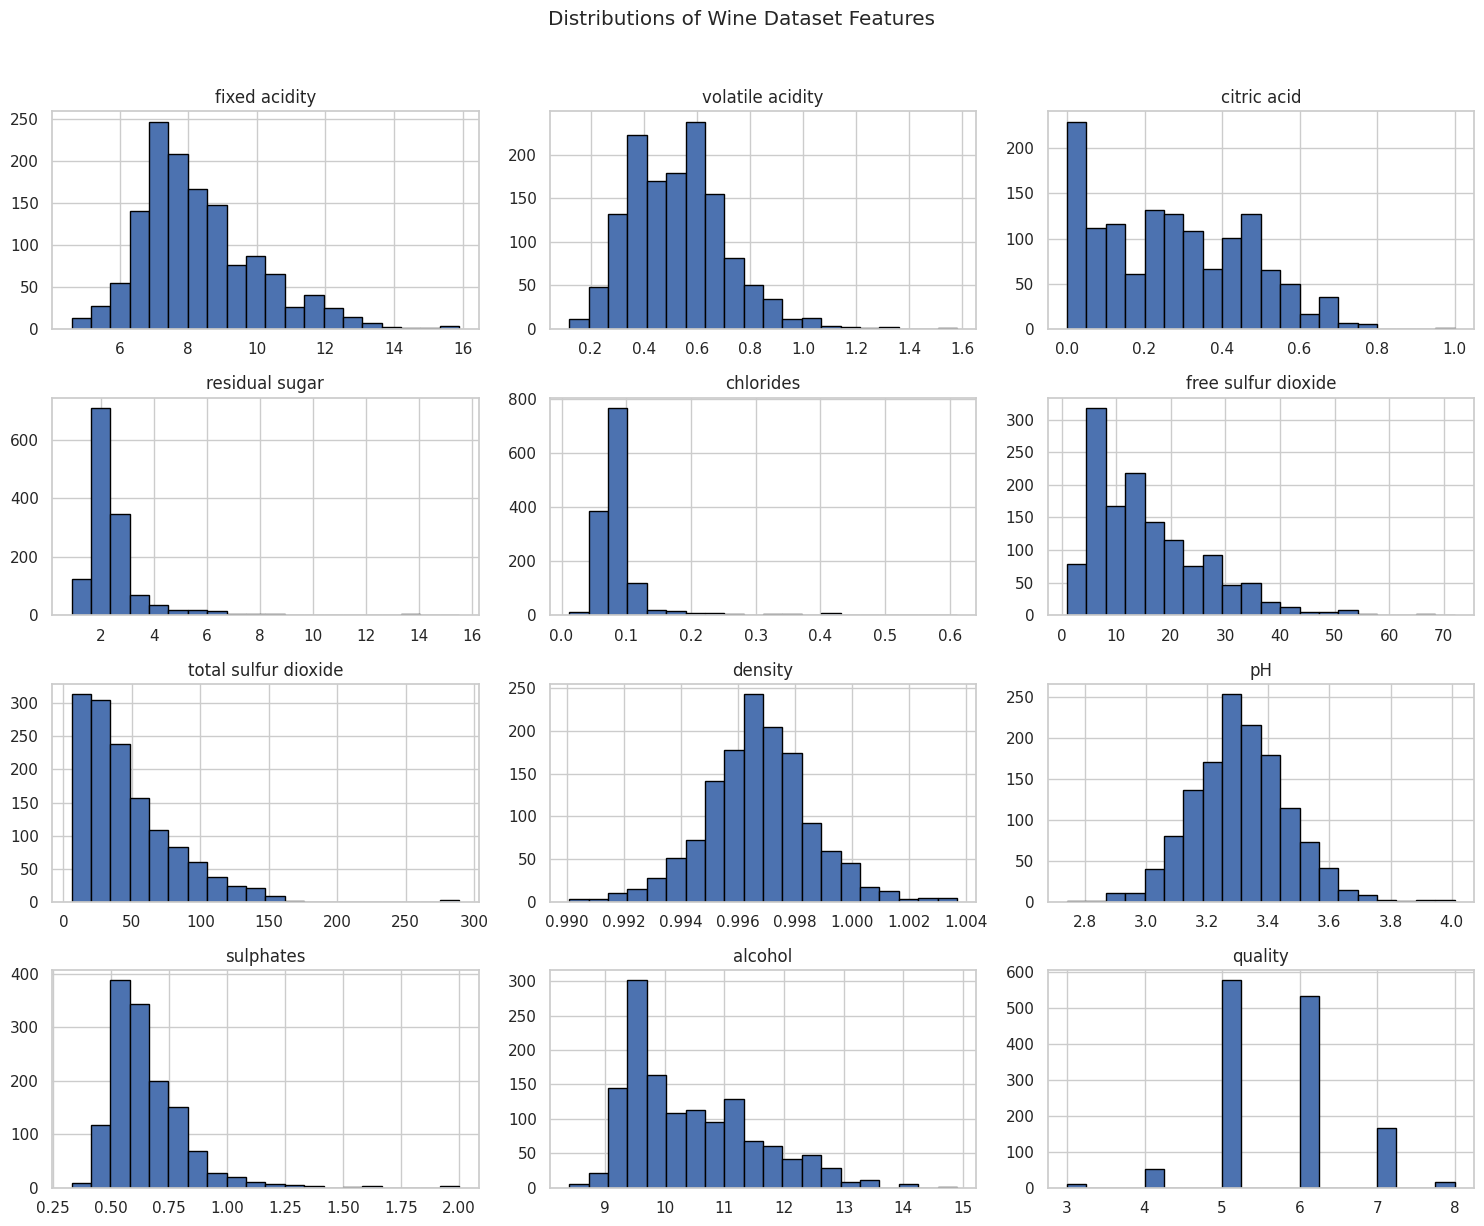

In [8]:
df.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.suptitle("Distributions of Wine Dataset Features", y=1.02)
plt.tight_layout()
plt.show()

### 8.3 Correlation between features
A correlation heatmap shows the strength and direction of linear relationships. Correlation does not prove causation.

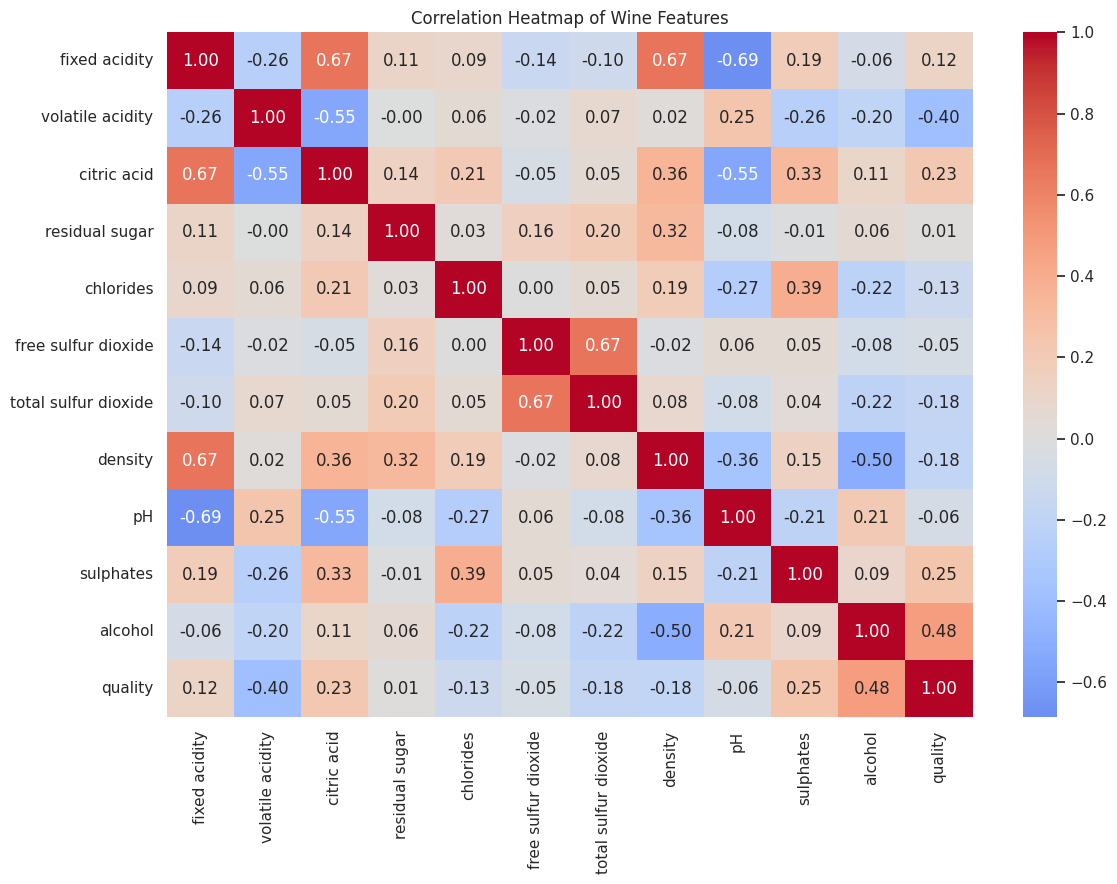

Features most positively correlated with quality:


,quality
alcohol,0.480343
sulphates,0.248835
citric acid,0.228057
fixed acidity,0.119024
residual sugar,0.013640


Features most negatively correlated with quality:


,quality
volatile acidity,-0.395214
density,-0.184252
total sulfur dioxide,-0.177855
chlorides,-0.130988
pH,-0.055245


In [9]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Wine Features")
plt.tight_layout()
plt.show()

print("Features most positively correlated with quality:")
display(correlation["quality"].drop("quality").sort_values(ascending=False).head(5))
print("Features most negatively correlated with quality:")
display(correlation["quality"].drop("quality").sort_values().head(5))

### 8.4 Alcohol content and wine quality
Compare alcohol content across quality scores using a box plot.

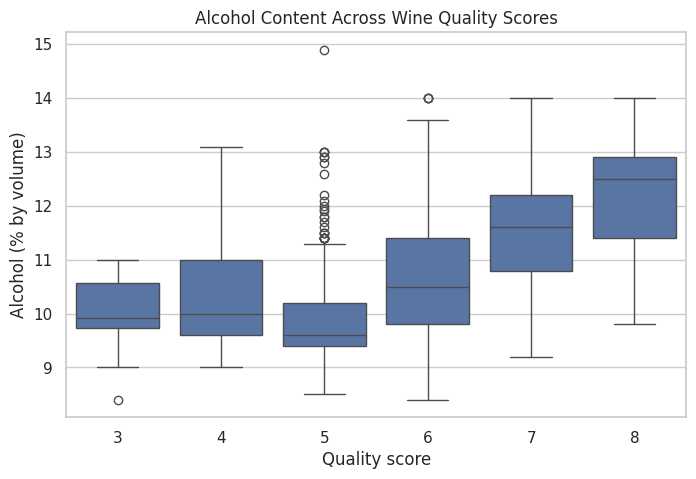

,Average alcohol content
quality,
3,9.96
4,10.27
5,9.89
6,10.66
7,11.49
8,12.16


In [10]:
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol Content Across Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Alcohol (% by volume)")
plt.show()

display(df.groupby("quality")["alcohol"].mean().round(2).rename("Average alcohol content"))

### 8.5 Volatile acidity and wine quality
Explore how volatile acidity varies across quality scores.

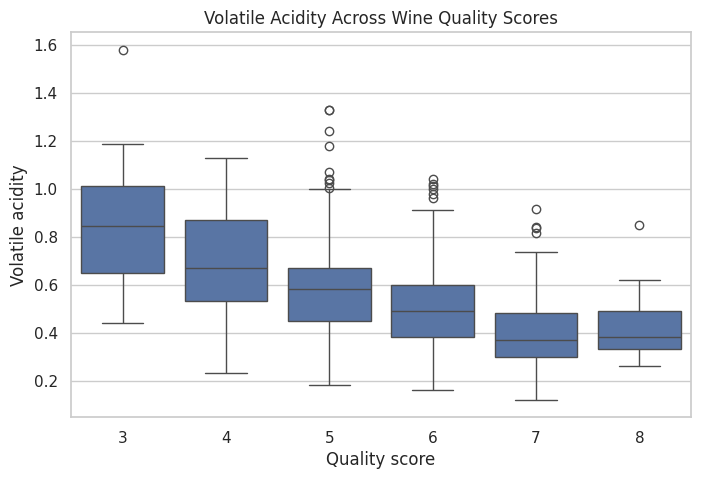

,Average volatile acidity
quality,
3,0.885
4,0.694
5,0.579
6,0.496
7,0.404
8,0.428


In [11]:
sns.boxplot(data=df, x="quality", y="volatile acidity")
plt.title("Volatile Acidity Across Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Volatile acidity")
plt.show()

display(df.groupby("quality")["volatile acidity"].mean().round(3).rename("Average volatile acidity"))

### 8.6 Alcohol versus quality
A scatter plot helps visualize the relationship between alcohol content and quality. The trend line is descriptive and should not be interpreted as proof of causation.

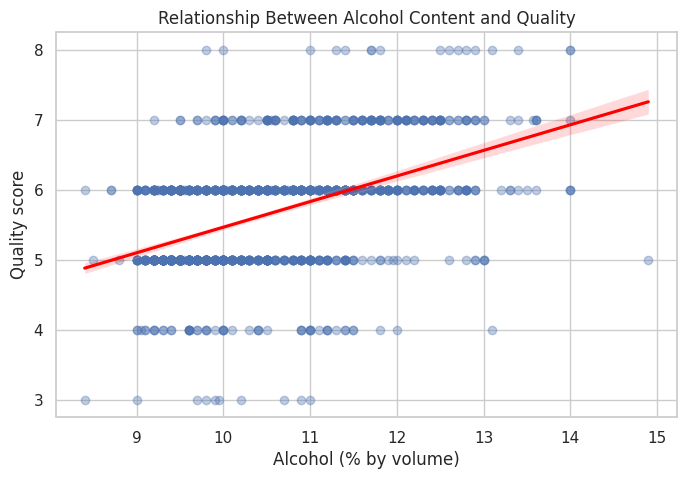

In [12]:
sns.regplot(data=df, x="alcohol", y="quality",
            scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
plt.title("Relationship Between Alcohol Content and Quality")
plt.xlabel("Alcohol (% by volume)")
plt.ylabel("Quality score")
plt.show()

## 9. Key findings and insights
The following summary is calculated from the cleaned dataset, so the values reflect the records retained after duplicate removal.

In [13]:
print("Number of records analysed:", len(df))
print("Average quality score:", round(df["quality"].mean(), 2))
print("Most common quality score:", int(df["quality"].mode().iloc[0]))
print("Average alcohol content:", round(df["alcohol"].mean(), 2))

quality_alcohol_corr = df["alcohol"].corr(df["quality"])
quality_volatile_corr = df["volatile acidity"].corr(df["quality"])
print("Correlation: alcohol vs quality:", round(quality_alcohol_corr, 3))
print("Correlation: volatile acidity vs quality:", round(quality_volatile_corr, 3))

best_quality = df["quality"].max()
lowest_quality = df["quality"].min()
print("Quality score range:", lowest_quality, "to", best_quality)

print("\nMean alcohol by quality:")
display(df.groupby("quality")["alcohol"].mean().round(2))
print("\nMean volatile acidity by quality:")
display(df.groupby("quality")["volatile acidity"].mean().round(3))

Number of records analysed: 1359
Average quality score: 5.62
Most common quality score: 5
Average alcohol content: 10.43
Correlation: alcohol vs quality: 0.48
Correlation: volatile acidity vs quality: -0.395
Quality score range: 3 to 8

Mean alcohol by quality:


,alcohol
quality,
3,9.96
4,10.27
5,9.89
6,10.66
7,11.49
8,12.16



Mean volatile acidity by quality:


,volatile acidity
quality,
3,0.885
4,0.694
5,0.579
6,0.496
7,0.404
8,0.428


## 10. Conclusion
This exploratory analysis examined the red wine quality dataset through data inspection, cleaning, preprocessing, statistical summaries, and visualizations.

Use the charts and calculated values above to support these conclusions:
- The quality score distribution shows which wine ratings are most common and whether the dataset is balanced across ratings.
- The correlation analysis identifies features that have stronger positive or negative linear associations with quality.
- The box plots help compare alcohol content and volatile acidity across quality groups.
- Potential outliers were identified using the IQR rule. They were not automatically removed because unusual measurements may be genuine observations.

**Overall conclusion:** Wine quality is associated with several physicochemical properties, but these relationships are not proof that any single property causes a higher or lower quality rating. Further statistical testing or predictive modelling would be needed to investigate those relationships more deeply.

## 11. Future scope
- Build a machine learning model to predict wine quality.
- Compare models such as Linear Regression, Decision Tree and Random Forest.
- Evaluate model performance using suitable metrics.
- Investigate feature importance and validate findings on unseen data.

---
**End of Project**